
# 16 — Combined system: v1 + v2 together (no training)

Notebook 15 showed v2 is much better on new generators and Stable Diffusion edits, but v1 is better on Flux edits and real photos.
This notebook **uses both**: all four trained networks (v1 unified, v1 edit finder, v2 unified, v2 edit finder) run on every image.

* **Decision (Real / Full AI / Partial AI):** a logistic regression on the heatmap statistics, fitted on the **validation** set.
  Three feature sets (v1 networks, v2 networks, all four) x two weightings (plain, every source equal) are compared by 5-fold
  cross-validation on validation; the score gives half weight to overall macro-F1 and half to the mean accuracy per source.
* **Edit mask and AI area:** a blend of the two edit-finder heatmaps; the blend weight and thresholds are chosen on **validation**.
* Nothing is tuned on the test sets. The final table puts v1, v2 and the combination side by side.

Cells 1–5 are the same as notebook 15 (they only read data that already exists; nothing is downloaded or generated).
Saves `final_hybrid_combo_deploy.pkl` → `python app.py --combo`. Takes about 20–30 minutes on the RTX 4050.


In [1]:
# ============================================================
# 1. Setup + configuration
# ============================================================
import os, sys, io, json, math, time, random, pickle, subprocess, importlib, warnings
from pathlib import Path
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive; drive.mount("/content/drive")
def ensure(module, pip_name=None):
    try: __import__(module)
    except ImportError: subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip_name or module])
for m in ["segmentation_models_pytorch:segmentation-models-pytorch", "datasets", "diffusers", "accelerate", "transformers"]:
    mod, _, pipn = m.partition(":"); ensure(mod, pipn or None)
import numpy as np, pandas as pd, torch, torch.nn.functional as F, matplotlib.pyplot as plt
import segmentation_models_pytorch as smp
from PIL import Image
from tqdm.auto import tqdm
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
warnings.filterwarnings("ignore"); Image.MAX_IMAGE_PIXELS = None
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30)

PROJECT_DIR = (Path("/content/drive/MyDrive/AI_Image_Project") if IN_COLAB
               else Path(os.environ.get("AI_PROJECT_DIR", r"C:\AI_Image_Project")))   # <- laptop folder
BASE_DIR = PROJECT_DIR / "Partial_AI_5000"
FEATURES_DIR, LOC_FEATURES_DIR = PROJECT_DIR / "features", PROJECT_DIR / "features" / "localization"
LOC_MODELS_DIR = PROJECT_DIR / "saved_models" / "localization"
EXTRA = PROJECT_DIR / "extra_train"; OUT_DIR = PROJECT_DIR / "results" / "v2"
EXTRA.mkdir(exist_ok=True); OUT_DIR.mkdir(parents=True, exist_ok=True)

CFG = dict(
    SEED=42, MAX_SIDE=1024,
    ARCH="Unet", ENCODER="resnet34",
    V1_UNIFIED="unified_Unet_resnet34_crop384", V1_LOC="Unet_resnet34_crop512_plusbbox_clean",   # v1 models (start points)
    COCOAI_SKIP_ROWS=200, COCOAI_ROWS=600, TRAIN_GENERATORS=["sd2.1", "sdxl", "sd3"],          # SD3.5, DALL-E 3, Midjourney stay unseen
    N_SD_TRAIN=600, N_SD_VAL=60,
    SD_PROMPTS=["a photo", "an object", "a person", "an animal", "a plate of food", "a car", "a plant", "a bag", "a chair", "a sign"],
    # localization fine-tune (Flux + SD edits)
    LOC_CROP=512, LOC_EPOCHS=15, LOC_SAMPLES=2000, LOC_LR=1e-4, LOC_SHARE={"partial": 0.5, "sdinpaint": 0.5},
    # unified fine-tune (all sources)
    UNI_CROP=384, UNI_EPOCHS=15, UNI_SAMPLES=3000, UNI_LR=1e-4,
    UNI_SHARE={"coco": 1/9, "original": 1/9, "cocoai_real": 1/9, "diffusiondb": 1/6, "cocoai_fake": 1/6, "partial": 1/6, "sdinpaint": 1/6},
    SCALE_PROB=0.5, SCALE_RANGE=(0.6, 1.0), JPEG_PROB=0.5, JPEG_Q=(60, 95), POS_CROP_PROB=0.7,
    WEIGHT_DECAY=1e-4, PATIENCE=5, VAL_PER_CLASS=150, TTA=True,
)
vram = torch.cuda.get_device_properties(0).total_memory / 1e9 if torch.cuda.is_available() else 0
CFG["LOC_BATCH"] = 12 if vram >= 14 else 6 if vram > 0 else 2
CFG["UNI_BATCH"] = 16 if vram >= 14 else 8 if vram > 0 else 4
CFG["NUM_WORKERS"] = 2 if IN_COLAB else min(4, os.cpu_count() or 2)    # Windows: set 0 if a worker error appears
LOC2, UNI2 = f'loc_v2_{CFG["ENCODER"]}', f'unified_v2_{CFG["ENCODER"]}'
DEPLOY_V1, DEPLOY_V2 = LOC_MODELS_DIR / "final_hybrid_deploy.pkl", LOC_MODELS_DIR / "final_hybrid_v2_deploy.pkl"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu"); USE_AMP = device.type == "cuda"
random.seed(CFG["SEED"]); np.random.seed(CFG["SEED"]); torch.manual_seed(CFG["SEED"])
CLASS_NAMES = ["Real", "Full AI", "Partial AI"]
need = [DEPLOY_V1, LOC_MODELS_DIR / f'{CFG["V1_UNIFIED"]}_best.pth', LOC_MODELS_DIR / f'{CFG["V1_LOC"]}_best.pth',
        LOC_MODELS_DIR / f'{CFG["V1_LOC"]}_deploy.pth', PROJECT_DIR / "ood_test" / "partA" / "index.csv",
        PROJECT_DIR / "ood_test" / "partB" / "index.csv", LOC_FEATURES_DIR / "mask_audit.csv", PROJECT_DIR / "COCO_5000",
        PROJECT_DIR / "DiffusionDB_5000"]
missing = [str(p) for p in need if not p.exists()]
assert not missing, "Missing (run notebooks 13 and 14 first):\n  " + "\n  ".join(missing)
print("Device:", device, "| v2 runs:", LOC2, UNI2)

Device: cuda | v2 runs: loc_v2_resnet34 unified_v2_resnet34


In [2]:
# ============================================================
# 2. Main table (same as notebook 13): COCO, originals, DiffusionDB, Flux edits - source-photo split
# ============================================================
pairs = pd.read_csv(BASE_DIR / "pairs.csv"); pairs["pairs_row"] = np.arange(len(pairs))
audit = pd.read_csv(LOC_FEATURES_DIR / "mask_audit.csv").set_index("row")
a = audit.loc[pairs["pairs_row"].to_numpy()]
use_csv = (a["verdict"] == "ok").to_numpy()
use_alt = ((~use_csv) & (a["alt_verdict"] == "ok").to_numpy()) if "alt_verdict" in a else np.zeros(len(a), bool)
alt_paths = a["alt_mask_path"].astype(str).to_numpy() if "alt_mask_path" in a else pairs["mask_path"].to_numpy()
pairs["verified_mask"] = np.where(use_csv, pairs["mask_path"], np.where(use_alt, alt_paths, ""))
segm = pairs[pairs.mask_type == "segm"].reset_index(drop=True)
SRC_SPLIT = {}
for name in ("val", "test"):
    for s in segm["source_id"].to_numpy()[np.load(LOC_FEATURES_DIR / f"{name}_idx.npy")]:
        SRC_SPLIT[int(s)] = name
src_split = lambda s: SRC_SPLIT.get(int(s), "train")

rows = []
for r in pairs.itertuples():
    rows.append(dict(path=str(BASE_DIR / r.manipulated_path), label=2, kind="partial", mtype=r.mask_type,
                     mask=str(BASE_DIR / r.verified_mask) if r.verified_mask else "", split=src_split(r.source_id)))
for op, s in pairs.groupby("original_path")["source_id"].first().items():
    rows.append(dict(path=str(BASE_DIR / op), label=0, kind="original", mtype="", mask="", split=src_split(s)))
paths15 = np.load(FEATURES_DIR / "image_paths_15k.npy", allow_pickle=True); y15 = np.load(FEATURES_DIR / "y_labels_15k.npy")
split15 = np.empty(len(y15), dtype=object)
for name in ("train", "val", "test"): split15[np.load(FEATURES_DIR / f"{name}_idx.npy")] = name
def local(p):
    p = str(p).replace("\\", "/"); k = "AI_Image_Project/"
    return str(PROJECT_DIR / p.split(k, 1)[1]) if k in p else p
for i in np.where(y15 <= 1)[0]:
    p = local(paths15[i]); stem = Path(p).stem; sp = split15[i]
    if y15[i] == 0 and stem.isdigit() and int(stem) in SRC_SPLIT: sp = SRC_SPLIT[int(stem)]
    rows.append(dict(path=p, label=int(y15[i]), kind="coco" if y15[i] == 0 else "diffusiondb", mtype="", mask="", split=sp))
DF = pd.DataFrame(rows); DF = DF[DF["path"].map(lambda p: Path(p).exists())].reset_index(drop=True)
print(pd.crosstab(DF.kind, DF.split).to_string())

split        test  train  val
kind                         
coco          589   3817  594
diffusiondb   500   4000  500
original      113   1333  112
partial       429   4073  498


In [3]:
# ============================================================
# 3. New Full-AI data: COCO_AI rows NOT used in notebook 14 (real + SD 2.1 / SDXL / SD 3 only)
# ============================================================
from datasets import load_dataset
COLS = {"coco_image": "real_coco", "sd3_image": "sd3", "sd21_image": "sd2.1", "sdxl_image": "sdxl"}
def ahash(img, n=16):
    a_ = np.asarray(img.convert("L").resize((n, n), Image.Resampling.BILINEAR), np.float32); return (a_ > a_.mean()).flatten()
cocoai_dir = EXTRA / "cocoai"
if not (cocoai_dir / "index.csv").exists():
    known = []                                   # our own photos: never add one of them again as a 'new' real photo
    for f in tqdm(list((PROJECT_DIR / "COCO_5000").glob("*.jpg")) + list((BASE_DIR / "Original").glob("*.png")), desc="Hashing own photos"):
        try: known.append(ahash(Image.open(f)))
        except Exception: pass
    known = np.stack(known)
    stream = load_dataset("NasrinImp/COCO_AI", split="train", streaming=True).skip(CFG["COCOAI_SKIP_ROWS"])
    out, kept = [], 0
    for r in tqdm(stream, total=int(CFG["COCOAI_ROWS"] * 1.2), desc="Streaming COCO_AI"):
        if kept >= CFG["COCOAI_ROWS"]: break
        real = r.get("coco_image")
        if real is None or (np.abs(known ^ ahash(real)[None]).sum(1) <= 12).any(): continue
        split = "val" if kept % 7 == 0 else "train"
        for col, name in COLS.items():
            if name != "real_coco" and name not in CFG["TRAIN_GENERATORS"]: continue
            im = r.get(col)
            if im is None: continue
            d = cocoai_dir / name; d.mkdir(parents=True, exist_ok=True); p = d / f"{kept:04d}.png"; im.convert("RGB").save(p)
            out.append(dict(path=str(p), label=0 if name == "real_coco" else 1, kind="cocoai_real" if name == "real_coco" else "cocoai_fake",
                            mtype=name, mask="", split=split))
        kept += 1
    pd.DataFrame(out).to_csv(cocoai_dir / "index.csv", index=False)
COCOAI = pd.read_csv(cocoai_dir / "index.csv").fillna("")
print(pd.crosstab([COCOAI.kind, COCOAI.mtype], COCOAI.split).to_string())

split                  train  val
kind        mtype                
cocoai_fake sd2.1        514   86
            sd3          514   86
            sdxl         514   86
cocoai_real real_coco    514   86


In [4]:
# ============================================================
# 4. New Partial-AI data: Stable Diffusion 1.5 inpainting of TRAIN (and VAL) photos inside their verified masks
#    Resumable: already generated images are skipped.
# ============================================================
sd_dir = EXTRA / "sdinpaint"; sd_dir.mkdir(exist_ok=True)
ok_rows = pairs[(audit.loc[pairs.pairs_row, "verdict"].to_numpy() == "ok")].copy()      # verified mask, same-size original
ok_rows["split"] = ok_rows.source_id.map(src_split)
plan = pd.concat([ok_rows[ok_rows.split == "train"].sample(min(CFG["N_SD_TRAIN"], (ok_rows.split == "train").sum()), random_state=1),
                  ok_rows[ok_rows.split == "val"].sample(min(CFG["N_SD_VAL"], (ok_rows.split == "val").sum()), random_state=1)]).reset_index(drop=True)
todo = [k for k in range(len(plan)) if not (sd_dir / f"sd_{k:04d}.png").exists()]
print(f"SD edits planned: {len(plan)} | still to generate: {len(todo)}")
if todo:
    from diffusers import StableDiffusionInpaintPipeline
    dtype = torch.float16 if torch.cuda.is_available() else torch.float32; pipe = None
    for repo in ["stable-diffusion-v1-5/stable-diffusion-inpainting", "runwayml/stable-diffusion-inpainting"]:
        for kw in ({"variant": "fp16"}, {}):
            try: pipe = StableDiffusionInpaintPipeline.from_pretrained(repo, torch_dtype=dtype, safety_checker=None, **kw); break
            except Exception as e: print(f"  could not load {repo} {kw}: {str(e)[:100]}")
        if pipe is not None: break
    assert pipe is not None, "Could not load the SD 1.5 inpainting model (notebook 14 downloaded it - check the internet connection)"
    pipe = pipe.to(device); pipe.enable_attention_slicing(); pipe.set_progress_bar_config(disable=True)
    rng = random.Random(CFG["SEED"])
    prompts = [rng.choice(CFG["SD_PROMPTS"]) for _ in range(len(plan))]
    for k in tqdm(todo, desc="SD inpainting"):
        r = plan.iloc[k]
        orig = Image.open(BASE_DIR / r.original_path).convert("RGB"); mask = Image.open(BASE_DIR / r.mask_path).convert("L")
        if mask.size != orig.size: mask = mask.resize(orig.size, Image.Resampling.NEAREST)
        W, H = orig.size; s = 512 / max(W, H); w8, h8 = max(64, int(W * s) // 8 * 8), max(64, int(H * s) // 8 * 8)
        g = torch.Generator(device=device).manual_seed(1000 + k)
        res = pipe(prompt=prompts[k], image=orig.resize((w8, h8), Image.Resampling.BICUBIC), mask_image=mask.resize((w8, h8), Image.Resampling.NEAREST),
                   num_inference_steps=25, guidance_scale=7.5, generator=g).images[0].resize((W, H), Image.Resampling.BICUBIC)
        m = np.asarray(mask) > 127; edited = np.asarray(orig).copy(); edited[m] = np.asarray(res)[m]
        mask.save(sd_dir / f"mask_{k:04d}.png"); Image.fromarray(edited).save(sd_dir / f"sd_{k:04d}.png")   # image last = complete
    del pipe; torch.cuda.empty_cache()
SD = pd.DataFrame([dict(path=str(sd_dir / f"sd_{k:04d}.png"), label=2, kind="sdinpaint", mtype="sd", mask=str(sd_dir / f"mask_{k:04d}.png"),
                        split=plan.iloc[k].split) for k in range(len(plan)) if (sd_dir / f"sd_{k:04d}.png").exists()])
print(SD.groupby("split").size().to_string())

DF2 = pd.concat([DF, COCOAI, SD], ignore_index=True)
DF2["has_mask"] = DF2["mask"] != ""
print("\nAll data (v2):"); print(pd.crosstab([DF2.kind, DF2.label], DF2.split, margins=True).to_string())

SD edits planned: 660 | still to generate: 0


split
train    600
val       60

All data (v2):
split              test  train   val    All
kind        label                          
coco        0       589   3817   594   5000
cocoai_fake 1         0   1542   258   1800
cocoai_real 0         0    514    86    600
diffusiondb 1       500   4000   500   5000
original    0       113   1333   112   1558
partial     2       429   4073   498   5000
sdinpaint   2         0    600    60    660
All                1631  15879  2108  19618


In [5]:
# ============================================================
# 5. Data loading module (same augmentations as notebook 13) + model / loss / evaluation helpers
# ============================================================
MODULE = r"""
import io, random
import numpy as np, torch
from PIL import Image
Image.MAX_IMAGE_PIXELS = None
IGNORE = 255
def load_resized(path, max_side):
    im = Image.open(path).convert("RGB"); s = min(1.0, max_side / max(im.size))
    if s < 1: im = im.resize((max(1, round(im.size[0] * s)), max(1, round(im.size[1] * s))), Image.Resampling.BICUBIC)
    return im
def target_mask(label, mask_path, size):
    w, h = size
    if label == 0: return np.zeros((h, w), np.uint8)
    if label == 1: return np.ones((h, w), np.uint8)
    m = Image.open(mask_path).convert("L")
    if m.size != size: m = m.resize(size, Image.Resampling.NEAREST)
    return (np.asarray(m) > 127).astype(np.uint8)
def jpeg(img, q):
    b = io.BytesIO(); img.save(b, "JPEG", quality=int(q)); b.seek(0); return Image.open(b).convert("RGB")
class TrainSet(torch.utils.data.Dataset):
    def __init__(self, items, cfg, crop): self.items, self.c, self.crop = items, cfg, crop
    def __len__(self): return len(self.items)
    def __getitem__(self, k):
        for _ in range(10):
            try: return self._get(k)
            except Exception: k = random.randrange(len(self.items))
        raise RuntimeError("10 unreadable images in a row")
    def _get(self, k):
        path, label, mpath = self.items[k]; c = self.c; crop = self.crop
        img = load_resized(path, c["MAX_SIDE"])
        if random.random() < c["SCALE_PROB"]:
            s = random.uniform(*c["SCALE_RANGE"]); img = img.resize((max(1, round(img.size[0] * s)), max(1, round(img.size[1] * s))), Image.Resampling.BICUBIC)
        m = target_mask(label, mpath, img.size); a = np.asarray(img); H, W = m.shape
        if H < crop or W < crop:
            ph, pw = max(0, crop - H), max(0, crop - W)
            a = np.pad(a, ((0, ph), (0, pw), (0, 0))); m = np.pad(m, ((0, ph), (0, pw)), constant_values=IGNORE); H, W = m.shape
        if label == 2 and random.random() < c["POS_CROP_PROB"] and (m == 1).any():
            ys, xs = np.nonzero(m == 1); j = random.randrange(len(ys)); y, x = ys[j], xs[j]
            y0 = int(np.clip(y - random.randrange(crop), 0, H - crop)); x0 = int(np.clip(x - random.randrange(crop), 0, W - crop))
        else:
            y0, x0 = random.randint(0, H - crop), random.randint(0, W - crop)
        a = a[y0:y0 + crop, x0:x0 + crop]; m = m[y0:y0 + crop, x0:x0 + crop]
        if random.random() < 0.5: a, m = a[:, ::-1], m[:, ::-1]
        if random.random() < c["JPEG_PROB"]: a = np.asarray(jpeg(Image.fromarray(np.ascontiguousarray(a)), random.randint(*c["JPEG_Q"])))
        return (torch.from_numpy(np.ascontiguousarray(a).transpose(2, 0, 1).copy()), torch.from_numpy(np.ascontiguousarray(m).copy()), torch.tensor(label))
def worker_init(i):
    s = torch.initial_seed() % 2**32; random.seed(s + i); np.random.seed((s + i) % 2**32)
"""
Path("unified_ds_v2.py").write_text(MODULE)
if str(Path.cwd()) not in sys.path: sys.path.insert(0, str(Path.cwd()))
import unified_ds_v2 as uds; importlib.reload(uds)

def make_loader(df, crop, samples, shares, batch):
    items = list(zip(df.path, df.label, df["mask"]))
    w = (df.kind.map(shares) / df.kind.map(df.kind.value_counts())).fillna(0).to_numpy()
    sampler = torch.utils.data.WeightedRandomSampler(torch.tensor(w, dtype=torch.double), samples, replacement=True)
    return torch.utils.data.DataLoader(uds.TrainSet(items, CFG, crop), batch_size=batch, sampler=sampler, num_workers=CFG["NUM_WORKERS"],
                                       pin_memory=USE_AMP, drop_last=True, persistent_workers=CFG["NUM_WORKERS"] > 0, worker_init_fn=uds.worker_init)

MEAN = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1) * 255
STD = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1) * 255
THRS = np.round(np.r_[0.01, 0.02, 0.03, 0.04, np.arange(0.05, 0.951, 0.05)], 2)
def make_model(arch=None, enc=None):
    return smp.create_model(arch=arch or CFG["ARCH"], encoder_name=enc or CFG["ENCODER"], encoder_weights=None, in_channels=3, classes=1).to(device).to(memory_format=torch.channels_last)
def load_weights(model, path):
    model.load_state_dict(torch.load(path, map_location=device, weights_only=False)["model"]); return model.eval()
def norm(x): return ((x.to(device, non_blocking=True).float() - MEAN) / STD).contiguous(memory_format=torch.channels_last)
def unified_loss(logits, target, labels):
    logits = logits.float(); valid = (target != 255).float(); t = (target == 1).float()
    bce = (F.binary_cross_entropy_with_logits(logits, t, reduction="none") * valid).sum() / valid.sum().clamp(min=1)
    part = (labels == 2).view(-1, 1, 1, 1).float() * valid
    if part.sum() == 0: return bce
    p = torch.sigmoid(logits); dice = (2 * (p * t * part).sum() + 1) / ((p * part).sum() + (t * part).sum() + 1)
    return bce + (1 - dice)
@torch.no_grad()
def predict_prob(model, img_arr, tta=False):
    H, W = img_arr.shape[:2]
    x = norm(torch.from_numpy(np.array(img_arr)).permute(2, 0, 1)[None]); x = F.pad(x, (0, (-W) % 32, 0, (-H) % 32), mode="reflect")
    with torch.autocast(device.type, dtype=torch.float16, enabled=USE_AMP):
        p = torch.sigmoid(model(x).float())
        if tta: p = 0.5 * (p + torch.sigmoid(model(x.flip(-1)).float()).flip(-1))
    return p[0, 0, :H, :W].float()
def image_stats(p):
    f = p.flatten(); k = max(1, int(0.01 * f.numel()))
    q = torch.quantile(f[:: max(1, f.numel() // 200000)], torch.tensor([0.99, 0.95, 0.5], device=f.device))
    return np.array([(f > t).float().mean().item() for t in (0.1, 0.3, 0.5, 0.7, 0.9)] + [f.mean().item(), f.std().item(), f.max().item()]
                    + q.tolist() + [f.topk(k).values.mean().item()], np.float32)
@torch.no_grad()
def run_eval(model, df, tta=False, desc="eval"):
    model.eval(); torch.backends.cudnn.benchmark = False
    thr = torch.tensor(THRS, device=device, dtype=torch.float32).view(-1, 1, 1)
    keep, S, inter, pred, gt, npx, fracs = [], [], [], [], [], [], []
    for j, r in enumerate(tqdm(df.itertuples(), total=len(df), desc=desc, leave=False)):
        try: img = uds.load_resized(r.path, CFG["MAX_SIDE"])
        except Exception: continue
        p = predict_prob(model, np.asarray(img), tta); keep.append(j); S.append(image_stats(p)); npx.append(p.numel())
        fracs.append((p.unsqueeze(0) >= thr).float().mean((1, 2)).cpu().numpy())
        if r.label == 2 and r.mask:
            g = torch.from_numpy(uds.target_mask(2, r.mask, img.size)).to(device).bool(); pr = p.unsqueeze(0) >= thr
            inter.append((pr & g).sum((1, 2)).cpu().numpy()); pred.append(pr.sum((1, 2)).cpu().numpy()); gt.append(g.sum().item())
        else:
            inter.append(None); pred.append(None); gt.append(None)
    torch.backends.cudnn.benchmark = True
    sub = df.iloc[keep].reset_index(drop=True)
    return dict(df=sub, stats=np.stack(S), label=sub.label.to_numpy(), inter=inter, pred=pred, gt=gt, npx=np.array(npx, float), fracs=np.stack(fracs))
def pixel_f1(ev, t, kind=None, mtype=None):
    k = [i for i, g in enumerate(ev["gt"]) if g is not None and (kind is None or ev["df"].kind[i] == kind) and (mtype is None or ev["df"].mtype[i] == mtype)]
    if not k: return np.nan, np.nan, 0
    I = np.array([ev["inter"][i][t] for i in k]); P = np.array([ev["pred"][i][t] for i in k]); G = np.array([ev["gt"][i] for i in k])
    return float((2 * I / (P + G + 1e-9)).mean()), float(2 * I.sum() / (P.sum() + G.sum() + 1e-9)), len(k)
def make_clf(): return make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=3000))
def cv_class_f1(ev):
    n_min = np.bincount(ev["label"], minlength=3).min()
    pred = cross_val_predict(make_clf(), ev["stats"], ev["label"], cv=StratifiedKFold(min(5, max(2, n_min)), shuffle=True, random_state=0))
    return f1_score(ev["label"], pred, average="macro")

def train_phase(name, model, loader, epochs, lr, val_fn):
    # generic fine-tuning loop with best/last checkpoints, auto-resume and early stopping
    best_p, last_p = LOC_MODELS_DIR / f"{name}_best.pth", LOC_MODELS_DIR / f"{name}_last.pth"
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=CFG["WEIGHT_DECAY"])
    steps = len(loader); total = epochs * steps
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: min(1.0, (s + 1) / steps) * (0.02 + 0.98 * 0.5 * (1 + math.cos(math.pi * min(1.0, s / total)))))
    scaler = torch.amp.GradScaler(device.type, enabled=USE_AMP)
    start, best, bad, hist = 0, -1.0, 0, []
    if last_p.exists():
        ck = torch.load(last_p, map_location=device, weights_only=False)
        model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"]); sched.load_state_dict(ck["sched"]); scaler.load_state_dict(ck["scaler"])
        start, best, bad, hist = ck["epoch"], ck["best"], ck["bad"], ck["hist"]; print(f"{name}: resumed after epoch {start}")
    else:
        s0 = val_fn(model); best = s0["score"]; torch.save({"model": model.state_dict(), "epoch": 0}, best_p)
        print(f"{name}: starting point (v1 weights) validation score {best:.4f} " + str({k: round(v, 4) for k, v in s0.items()}))
    torch.backends.cudnn.benchmark = True
    for ep in range(start, epochs):
        if bad >= CFG["PATIENCE"]: print("Early stopping."); break
        model.train(); t0 = time.time(); tot = 0.0
        for x, y, lab in tqdm(loader, desc=f"{name} epoch {ep+1}/{epochs}", leave=False):
            y = y.to(device, non_blocking=True).unsqueeze(1); lab = lab.to(device); opt.zero_grad(set_to_none=True)
            with torch.autocast(device.type, dtype=torch.float16, enabled=USE_AMP): logits = model(norm(x))
            loss = unified_loss(logits, y, lab); scaler.scale(loss).backward(); scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0); scaler.step(opt); scaler.update(); sched.step(); tot += loss.item()
        s = val_fn(model); improved = s["score"] > best
        hist.append(dict(epoch=ep + 1, loss=tot / steps, **s, minutes=(time.time() - t0) / 60))
        if improved: best, bad = s["score"], 0; torch.save({"model": model.state_dict(), "epoch": ep + 1}, best_p)
        else: bad += 1
        torch.save({"model": model.state_dict(), "opt": opt.state_dict(), "sched": sched.state_dict(), "scaler": scaler.state_dict(),
                    "epoch": ep + 1, "best": best, "bad": bad, "hist": hist}, last_p)
        print(f"{name} ep {ep+1:02d} | loss {tot/steps:.4f} | " + " | ".join(f"{k} {v:.4f}" for k, v in s.items()) + f" | {(time.time()-t0)/60:.1f} min" + ("  *best*" if improved else ""))
    pd.DataFrame(hist).to_csv(OUT_DIR / f"{name}_history.csv", index=False)
    return load_weights(model, best_p)
print("Helpers ready")

Helpers ready


In [6]:
# ============================================================
# 6. Load the four trained networks (v1 + v2) - no training here
# ============================================================
assert DEPLOY_V2.exists() and (OUT_DIR / "v1_vs_v2_per_image.csv").exists(), "Run notebook 15 to the end first"
d1 = pickle.load(open(DEPLOY_V1, "rb")); d2 = pickle.load(open(DEPLOY_V2, "rb"))
DEPLOY_C = LOC_MODELS_DIR / "final_hybrid_combo_deploy.pkl"
def load_loc(run):
    d = torch.load(LOC_MODELS_DIR / f"{run}_deploy.pth", map_location=device, weights_only=False)
    m = make_model(d["cfg"]["ARCH"], d["cfg"]["ENCODER"]); m.load_state_dict(d["model"]); return m.eval()
NETS = {"uni1": load_weights(make_model(), LOC_MODELS_DIR / f'{d1["unified_run"]}_best.pth'), "loc1": load_loc(d1["loc07_run"]),
        "uni2": load_weights(make_model(), LOC_MODELS_DIR / f'{d2["unified_run"]}_best.pth'), "loc2": load_loc(d2["loc07_run"])}
ORDER = ["uni1", "loc1", "uni2", "loc2"]                      # 12 statistics each -> 48 features, in this order (the app uses the same)
FEATSETS = {"v1 networks": list(range(0, 24)), "v2 networks": list(range(24, 48)), "all four": list(range(0, 48))}
BLENDS = {"v1 edit finder": 0.0, "blend 0.25": 0.25, "average": 0.5, "blend 0.75": 0.75, "v2 edit finder": 1.0, "max": None}   # weight of v2
def blend_map(p1, p2, w): return torch.maximum(p1, p2) if w is None else (1 - w) * p1 + w * p2
print("Loaded:", d1["unified_run"], d1["loc07_run"], d2["unified_run"], d2["loc07_run"])

@torch.no_grad()
def collect(df, desc):
    # one pass per image: 4 networks (with flip TTA), 48 statistics, and edit-mask counts for every blend x threshold
    thr = torch.tensor(THRS, device=device, dtype=torch.float32).view(-1, 1, 1)
    keep, S, gt, npx = [], [], [], []
    rec = {b: dict(inter=[], pred=[], frac=[]) for b in BLENDS}
    for j, r in enumerate(tqdm(df.itertuples(), total=len(df), desc=desc)):
        try: img = uds.load_resized(r.path, CFG["MAX_SIDE"])
        except Exception: continue
        arr = np.asarray(img)
        p = {k: predict_prob(NETS[k], arr, True) for k in ORDER}
        keep.append(j); S.append(np.hstack([image_stats(p[k]) for k in ORDER])); npx.append(arr.shape[0] * arr.shape[1])
        g = None
        if r.label == 2 and isinstance(r.mask, str) and r.mask:
            g = torch.from_numpy(uds.target_mask(2, r.mask, img.size)).to(device).bool()
        gt.append(None if g is None else int(g.sum().item()))
        for b, w in BLENDS.items():
            pr = blend_map(p["loc1"], p["loc2"], w).unsqueeze(0) >= thr
            rec[b]["frac"].append(pr.float().mean((1, 2)).cpu().numpy())
            rec[b]["inter"].append(None if g is None else (pr & g).sum((1, 2)).cpu().numpy())
            rec[b]["pred"].append(None if g is None else pr.sum((1, 2)).cpu().numpy())
    sub = df.iloc[keep].reset_index(drop=True)
    for b in BLENDS: rec[b]["frac"] = np.stack(rec[b]["frac"])
    return dict(df=sub, stats=np.stack(S), label=sub.label.to_numpy(), gt=gt, npx=np.array(npx, float), rec=rec)

def img_f1(ev, b, t, i):
    return float(2 * ev["rec"][b]["inter"][i][t] / (ev["rec"][b]["pred"][i][t] + ev["gt"][i] + 1e-9))
def mean_f1(ev, b, t, kind):
    k = [i for i, g in enumerate(ev["gt"]) if g is not None and ev["df"].kind[i] == kind]
    return float(np.mean([img_f1(ev, b, t, i) for i in k])) if k else np.nan

Loaded: unified_Unet_resnet34_crop384 Unet_resnet34_crop512_plusbbox_clean unified_v2_resnet34 loc_v2_resnet34


In [7]:
# ============================================================
# 7. Choose everything on VALIDATION: feature set for the decision, edit-finder blend, mask and area thresholds
# ============================================================
ev_val = collect(DF2[DF2.split == "val"].reset_index(drop=True), "validation (4 networks)")
print("Validation images:", ev_val["df"].kind.value_counts().to_dict())

#   score = half overall macro-F1 (dominated by the big main sets) + half mean accuracy per source (every source counts equally:
#   COCO, originals, DiffusionDB, Flux edits, COCO_AI real, SD2.1/SDXL/SD3, SD edits) - the project goal is "any image"
yv, kv = ev_val["label"], ev_val["df"].kind.to_numpy()
cnt = pd.Series(kv).value_counts(); W_SRC = (len(kv) / (len(cnt) * pd.Series(kv).map(cnt))).to_numpy()
n_min = np.bincount(yv, minlength=3).min()
cv = StratifiedKFold(min(5, max(2, n_min)), shuffle=True, random_state=0)
def fit_clf(X, y, w): return make_clf().fit(X, y, logisticregression__sample_weight=w)
fs_rows = []
for name, idx in FEATSETS.items():
    for wname, w in (("plain", None), ("source-balanced", W_SRC)):
        X = ev_val["stats"][:, idx]; pred = np.empty_like(yv)
        for tr, te in cv.split(X, yv): pred[te] = fit_clf(X[tr], yv[tr], None if w is None else w[tr]).predict(X[te])
        per_src = pd.Series(pred == yv).groupby(kv).mean()
        mf1 = f1_score(yv, pred, average="macro")
        fs_rows.append(dict(features=name, weights=wname, cv_macroF1=mf1, cv_accuracy=(pred == yv).mean(),
                            mean_source_acc=per_src.mean(), score=0.5 * mf1 + 0.5 * per_src.mean(), **{f"acc {k}": v for k, v in per_src.items()}))
fs_tab = pd.DataFrame(fs_rows).set_index(["features", "weights"])
print("\nDecision - 5-fold CV on validation:"); print(fs_tab.round(3).to_string())
FEAT_NAME, W_NAME = fs_tab.score.idxmax(); FEAT_IDX = FEATSETS[FEAT_NAME]
CLF3 = fit_clf(ev_val["stats"][:, FEAT_IDX], yv, W_SRC if W_NAME == "source-balanced" else None)

bl_rows = []
vk = [i for i, g in enumerate(ev_val["gt"]) if g is not None]; true_v = np.array([100 * ev_val["gt"][i] / ev_val["npx"][i] for i in vk])
for b in BLENDS:
    sc = [np.nanmean([mean_f1(ev_val, b, t, "partial"), mean_f1(ev_val, b, t, "sdinpaint")]) for t in range(len(THRS))]
    t = int(np.nanargmax(sc)); ta = int(np.argmin([np.abs(100 * ev_val["rec"][b]["frac"][vk, u] - true_v).mean() for u in range(len(THRS))]))
    bl_rows.append(dict(blend=b, score=sc[t], F1_flux=mean_f1(ev_val, b, t, "partial"), F1_sd=mean_f1(ev_val, b, t, "sdinpaint"),
                        mask_t=float(THRS[t]), area_t=float(THRS[ta]), area_MAE=float(np.abs(100 * ev_val["rec"][b]["frac"][vk, ta] - true_v).mean())))
bl_tab = pd.DataFrame(bl_rows).set_index("blend"); print("\nEdit finder - validation (mean per-image F1 at the best threshold):"); print(bl_tab.round(4).to_string())
BLEND = bl_tab.score.idxmax(); MASK_T3, AREA_T3 = bl_tab.loc[BLEND, "mask_t"], bl_tab.loc[BLEND, "area_t"]
TM3, TA3 = int(np.where(THRS == MASK_T3)[0][0]), int(np.where(THRS == AREA_T3)[0][0])
print(f"\nChosen on validation -> decision: {FEAT_NAME} ({W_NAME} weights) | edit finder: {BLEND} | mask threshold {MASK_T3} | area threshold {AREA_T3}")

validation (4 networks):   0%|          | 0/2108 [00:00<?, ?it/s]

Validation images: {'coco': 594, 'diffusiondb': 500, 'partial': 498, 'cocoai_fake': 258, 'original': 112, 'cocoai_real': 86, 'sdinpaint': 60}



Decision - 5-fold CV on validation:
                             cv_macroF1  cv_accuracy  mean_source_acc  score  acc coco  acc cocoai_fake  acc cocoai_real  acc diffusiondb  acc original  acc partial  acc sdinpaint
features    weights                                                                                                                                                                
v1 networks plain                 0.818        0.827            0.746  0.782     0.880            0.748            0.837            0.998         0.589        0.733          0.433
            source-balanced       0.813        0.824            0.746  0.780     0.886            0.744            0.860            0.998         0.634        0.703          0.400
v2 networks plain                 0.864        0.873            0.854  0.859     0.889            0.973            0.919            0.994         0.545        0.741          0.917
            source-balanced       0.850        0.864           


Edit finder - validation (mean per-image F1 at the best threshold):
                 score  F1_flux   F1_sd  mask_t  area_t  area_MAE
blend                                                            
v1 edit finder  0.3365   0.5239  0.1491    0.03    0.45    1.9198
blend 0.25      0.5986   0.5503  0.6469    0.15    0.20    1.7143
average         0.6098   0.5380  0.6816    0.30    0.45    1.3395
blend 0.75      0.6000   0.5118  0.6882    0.45    0.50    1.4284
v2 edit finder  0.5840   0.4745  0.6935    0.60    0.60    1.5993
max             0.6047   0.5228  0.6867    0.55    0.85    1.3366

Chosen on validation -> decision: all four (plain weights) | edit finder: average | mask threshold 0.3 | area threshold 0.45


In [8]:
# ============================================================
# 8. Test: the combined system on the same sets as notebook 15, next to v1 and v2
# ============================================================
test = DF[DF.split == "test"].reset_index(drop=True).assign(group=lambda d: d.kind)
pa = pd.read_csv(PROJECT_DIR / "ood_test" / "partA" / "index.csv")
pa = pd.DataFrame(dict(path=pa.path, label=np.where(pa.expected == 0, 0, 1), mask="",
                       group=[("unseen gen: " if s in ("sd3.5", "dalle3", "midjourney6") else ("real: " if s == "real_coco" else "seen gen: ")) + s for s in pa.source]))
pb = pd.read_csv(PROJECT_DIR / "ood_test" / "partB" / "index.csv")
pbd = pd.concat([pd.DataFrame(dict(path=pb.sd_edit, label=2, mask=pb["mask"], group="SD inpaint edit")),
                 pd.DataFrame(dict(path=pb.flux_edit, label=2, mask=pb["mask"], group="Flux edit")),
                 pd.DataFrame(dict(path=pb.original, label=0, mask="", group="untouched original"))], ignore_index=True)

def score_combo(df, tag):
    ev = collect(df, tag); pred = CLF3.predict(ev["stats"][:, FEAT_IDX]); rows = []
    for i in range(len(ev["df"])):
        rows.append(dict(version="v1+v2", group=ev["df"].group[i], label=int(ev["label"][i]), pred=int(pred[i]),
                         mask_f1=img_f1(ev, BLEND, TM3, i) if ev["gt"][i] is not None else np.nan))
    return pd.DataFrame(rows)

new = pd.concat([score_combo(test, "main test"), score_combo(pa, "unseen generators"), score_combo(pbd, "SD vs Flux edits")], ignore_index=True)
res = pd.concat([pd.read_csv(OUT_DIR / "v1_vs_v2_per_image.csv"), new], ignore_index=True)
res.to_csv(OUT_DIR / "v1_v2_combo_per_image.csv", index=False)
VERS = ["v1", "v2", "v1+v2"]
tab = (res.assign(correct=lambda d: (d.pred == d.label).astype(float), flagged_ai=lambda d: (d.pred > 0).astype(float))
          .groupby(["group", "version"]).agg(images=("correct", "size"), correct=("correct", "mean"), flagged_as_AI=("flagged_ai", "mean"), mask_F1=("mask_f1", "mean"))
          .unstack("version"))
tab = tab.reindex(columns=pd.MultiIndex.from_product([["images", "correct", "flagged_as_AI", "mask_F1"], VERS]))
print("=" * 120); print("v1 vs v2 vs combined (correct = right class; flagged_as_AI = Full or Partial; mask_F1 for edits with a known mask)"); print("=" * 120)
print(tab.drop(columns="images").round(3).to_string())
tab.to_csv(OUT_DIR / "v1_v2_combo_summary.csv")
summ = []
for v in VERS:
    m = res[(res.version == v) & res.group.isin(["coco", "original", "diffusiondb", "partial"])]
    o = res[(res.version == v) & ~res.group.isin(["coco", "original", "diffusiondb", "partial"])]
    summ.append(dict(version=v, main_test_accuracy=(m.pred == m.label).mean(), main_test_macroF1=f1_score(m.label, m.pred, average="macro"),
                     new_sets_accuracy=(o.pred == o.label).mean(), partial_mask_F1=m[m.group == "partial"].mask_f1.mean(),
                     flux_edit_mask_F1=o[o.group == "Flux edit"].mask_f1.mean(), sd_edit_mask_F1=o[o.group == "SD inpaint edit"].mask_f1.mean()))
summ = pd.DataFrame(summ).set_index("version"); summ.to_csv(OUT_DIR / "v1_v2_combo_overall.csv")
print("\nOverall (main test = notebook 13 test set; new sets = notebook 14 COCO_AI + SD/Flux edits):"); print(summ.round(4).to_string())

main test:   0%|          | 0/1631 [00:00<?, ?it/s]

unseen generators:   0%|          | 0/350 [00:00<?, ?it/s]

SD vs Flux edits:   0%|          | 0/180 [00:00<?, ?it/s]

v1 vs v2 vs combined (correct = right class; flagged_as_AI = Full or Partial; mask_F1 for edits with a known mask)
                        correct               flagged_as_AI               mask_F1              
                             v1     v2  v1+v2            v1     v2  v1+v2      v1     v2  v1+v2
group                                                                                          
Flux edit                 0.617  0.633  0.600         0.617  0.633  0.617   0.501  0.431  0.494
SD inpaint edit           0.283  0.817  0.633         0.283  0.817  0.650   0.112  0.648  0.635
coco                      0.929  0.910  0.925         0.071  0.090  0.075     NaN    NaN    NaN
diffusiondb               0.990  0.992  0.996         0.990  0.992  0.996     NaN    NaN    NaN
original                  0.735  0.699  0.708         0.265  0.301  0.292     NaN    NaN    NaN
partial                   0.681  0.641  0.662         0.685  0.646  0.674   0.602  0.463  0.567
real: real_coco      

Saved final_hybrid_combo_deploy.pkl -> start the app with:  python app.py --combo


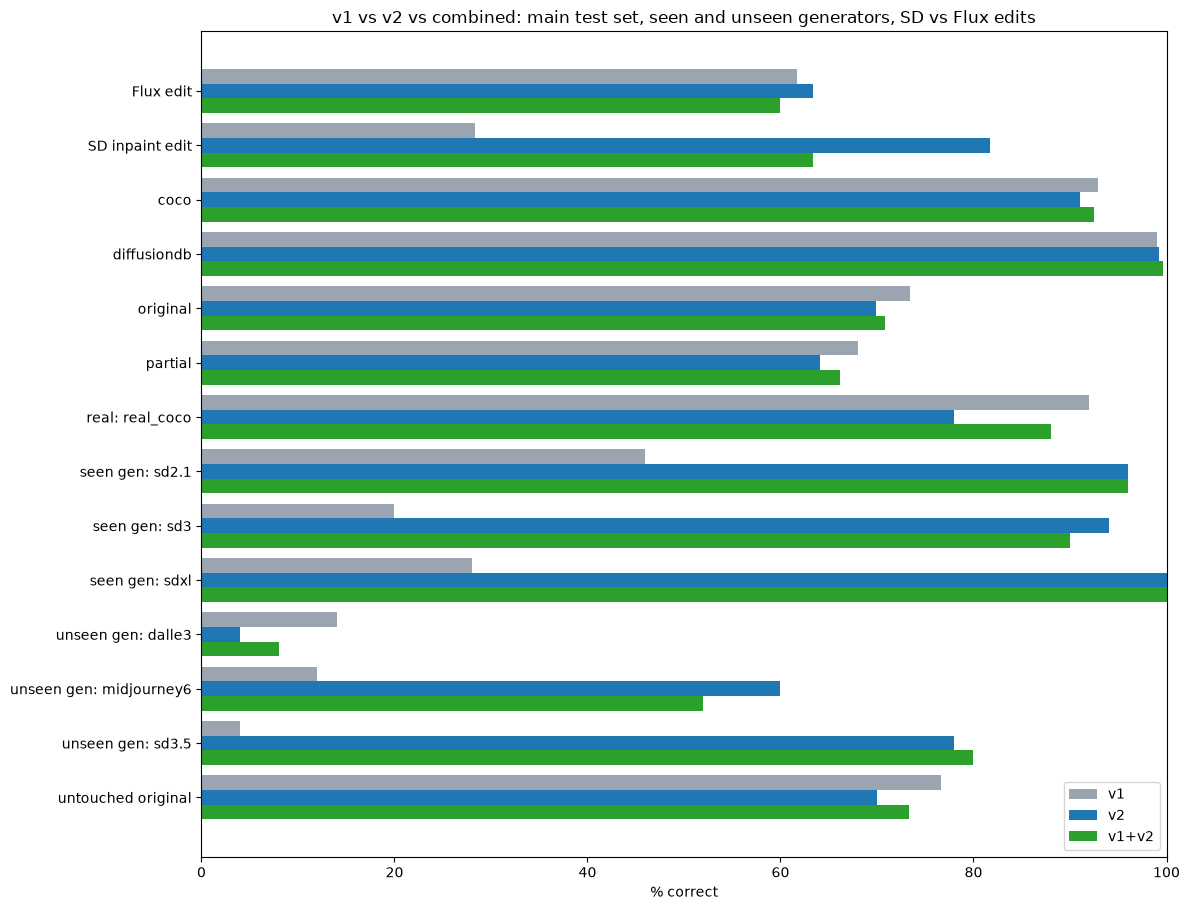

In [9]:
# ============================================================
# 9. Save the combined system for the app (python app.py --combo) + plot
# ============================================================
cfg_app = dict(d2["cfg"]); cfg_app["TTA"] = True
pickle.dump({"classifier": CLF3, "combo": True, "feat_idx": FEAT_IDX, "feature_set": FEAT_NAME, "weights": W_NAME,
             "unified_runs": [d1["unified_run"], d2["unified_run"]], "loc_runs": [d1["loc07_run"], d2["loc07_run"]],
             "loc_weight": BLENDS[BLEND], "blend": BLEND, "mask_t": float(MASK_T3), "area_t": float(AREA_T3), "cfg": cfg_app,
             "unified_run": d2["unified_run"], "loc07_run": d2["loc07_run"]}, open(DEPLOY_C, "wb"))
print("Saved", DEPLOY_C.name, "-> start the app with:  python app.py --combo")

c = tab["correct"].reset_index()
fig, ax = plt.subplots(figsize=(12, 0.55 * len(c) + 1.5)); y = np.arange(len(c))
for k, (v, col) in enumerate(zip(VERS, ["#9aa5b1", "#1f77b4", "#2ca02c"])):
    ax.barh(y + (k - 1) * 0.27, 100 * c[v], 0.27, label=v, color=col)
ax.set_yticks(y, c["group"]); ax.set_xlabel("% correct"); ax.set_xlim(0, 100); ax.legend(loc="lower right"); ax.invert_yaxis()
ax.set_title("v1 vs v2 vs combined: main test set, seen and unseen generators, SD vs Flux edits"); plt.tight_layout()
plt.savefig(OUT_DIR / "v1_v2_combo.png", dpi=110); plt.show()